In [1]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
!pip install streamlit pandas scikit-learn plotly shap matplotlib -q
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
!pip install streamlit
import streamlit as st
import pandas as pd
import pickle as pkl

In [2]:
df = pd.read_csv('Telco-Customer-Churn.csv')

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [6]:
df.isnull().sum(axis=0)

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


2026-09-29 07:58:24.037 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-29 07:58:24.179 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-29 07:58:24.381 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-09-29 07:58:24.383 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-29 07:58:24.384 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-29 07:58:24.478 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-29 07:58:24.652 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

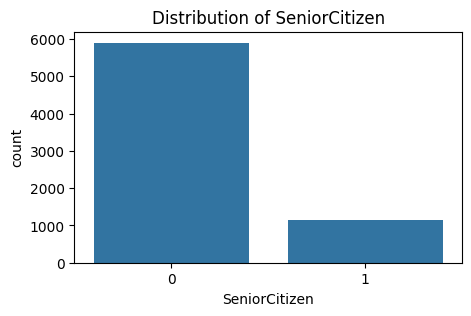

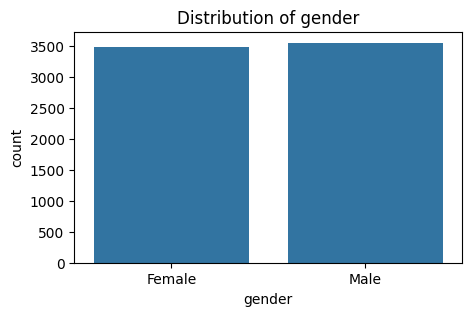

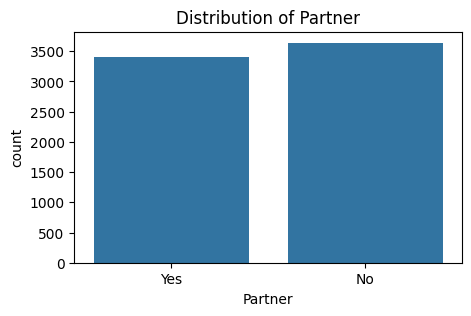

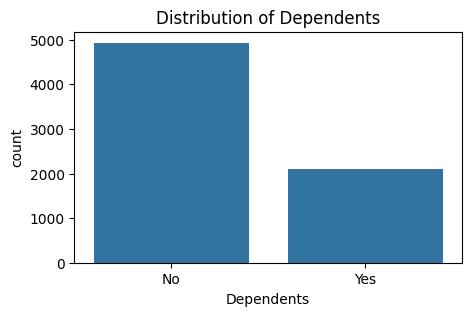

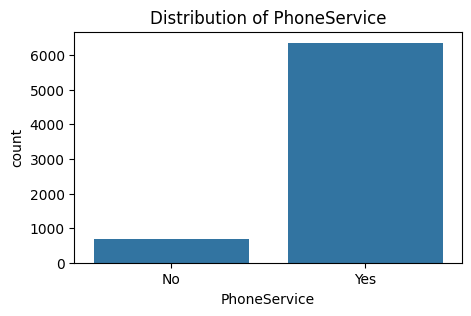

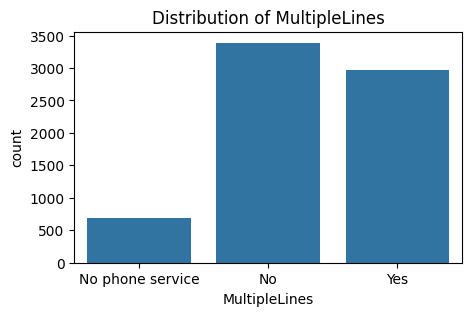

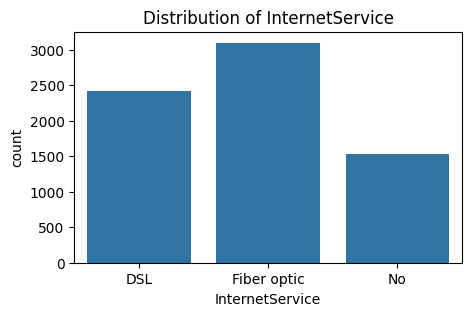

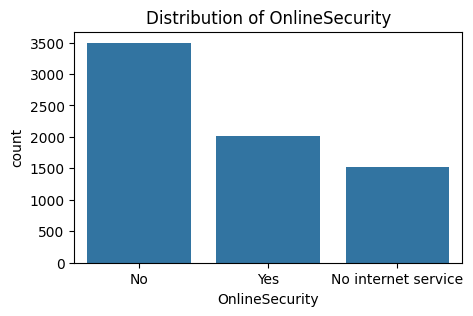

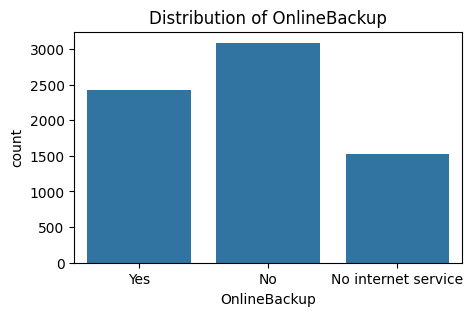

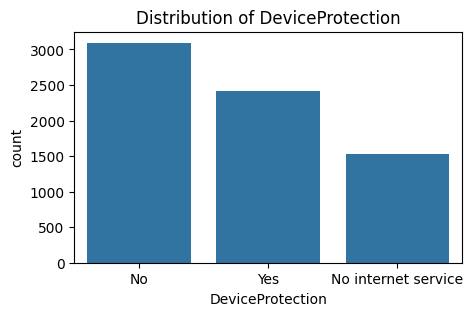

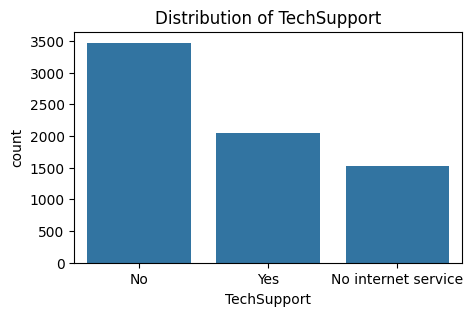

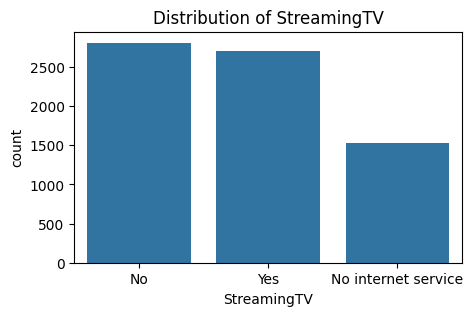

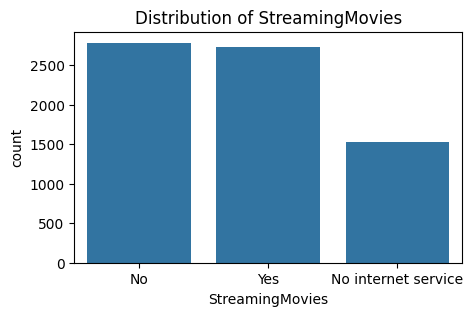

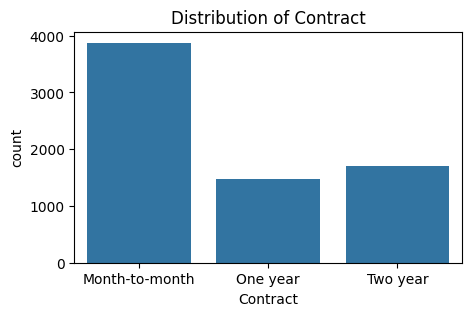

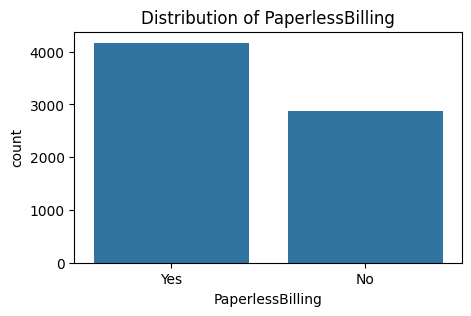

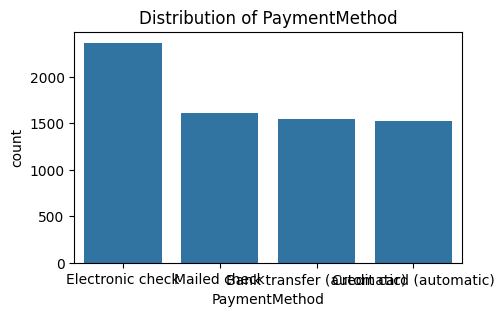

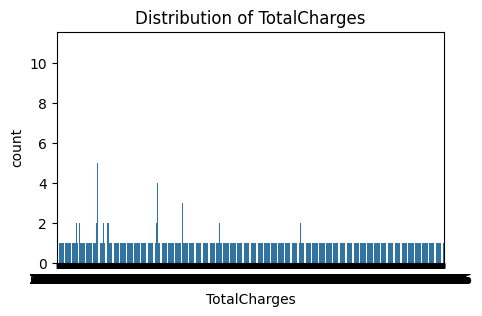

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
categorical_cols = df.select_dtypes(include='object').columns.tolist()
categorical_cols.remove('customerID')
categorical_cols.remove('Churn')

categorical_cols = ["SeniorCitizen"] + categorical_cols

for col in categorical_cols:
    fig, ax = plt.subplots(figsize=(5,3))
    sns.countplot(x=df[col], ax=ax)
    ax.set_title(f'Distribution of {col}')
    st.pyplot(fig)

In [9]:
df = pd.read_csv('Telco-Customer-Churn.csv')
for col in df.columns:
    print(col, df[col].unique())
    print("-"*50)

customerID ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
--------------------------------------------------
gender ['Female' 'Male']
--------------------------------------------------
SeniorCitizen [0 1]
--------------------------------------------------
Partner ['Yes' 'No']
--------------------------------------------------
Dependents ['No' 'Yes']
--------------------------------------------------
tenure [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
--------------------------------------------------
PhoneService ['No' 'Yes']
--------------------------------------------------
MultipleLines ['No phone service' 'No' 'Yes']
--------------------------------------------------
InternetService ['DSL' 'Fiber optic' 'No']
--------------------------------------------------
OnlineSec

In [10]:
encoders = {}

for col in categorical_cols:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col])
  encoders[col] = le

with open ("encoders.pkl", "wb") as f:
    pkl.dump(encoders, f)

In [11]:
encoders

{'SeniorCitizen': LabelEncoder(),
 'gender': LabelEncoder(),
 'Partner': LabelEncoder(),
 'Dependents': LabelEncoder(),
 'PhoneService': LabelEncoder(),
 'MultipleLines': LabelEncoder(),
 'InternetService': LabelEncoder(),
 'OnlineSecurity': LabelEncoder(),
 'OnlineBackup': LabelEncoder(),
 'DeviceProtection': LabelEncoder(),
 'TechSupport': LabelEncoder(),
 'StreamingTV': LabelEncoder(),
 'StreamingMovies': LabelEncoder(),
 'Contract': LabelEncoder(),
 'PaperlessBilling': LabelEncoder(),
 'PaymentMethod': LabelEncoder(),
 'TotalCharges': LabelEncoder()}

In [12]:
df['Churn'] = df['Churn'].map({'No':0, 'Yes':1})

In [13]:
def plot_histogram(df, column_name):
    plt.figure(figsize=(5,3))
    sns.histplot(df[column_name], kde=True)
    plt.title(f'Distribution of {column_name}')

    col_mean = df[column_name].mean()
    col_median = df[column_name].median()

    plt.axvline(col_mean, color='red', linestyle="--", label="Mean")
    plt.axvline(col_median, color="green", linestyle="--", label="Median")
    plt.legend()
    plt.show()

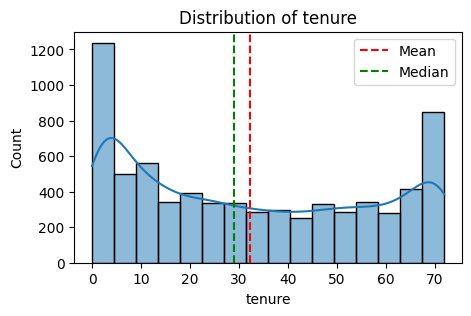

In [14]:
plot_histogram(df, 'tenure')

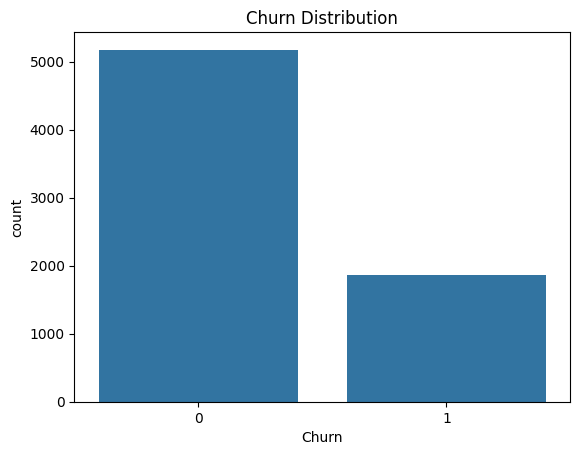

In [15]:
sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

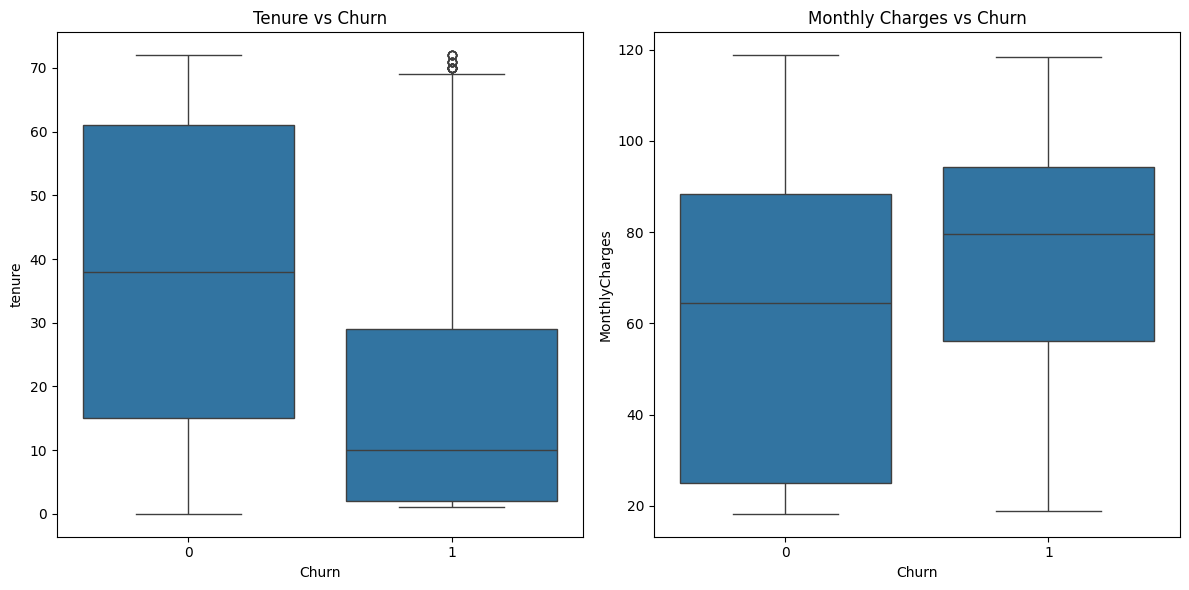

In [16]:
fig, axes = plt.subplots(1, 2, figsize = (12, 6))

sns.boxplot(x='Churn', y='tenure', ax = axes[0], data=df)
axes[0].set_title('Tenure vs Churn')

sns.boxplot(x='Churn', y='MonthlyCharges', ax = axes[1], data=df)
axes[1].set_title('Monthly Charges vs Churn')

plt.tight_layout()
plt.show()

In [17]:
corr = df.drop('customerID', axis=1).corr()['Churn'].sort_values(ascending=False)
print(corr)

Churn               1.000000
MonthlyCharges      0.193356
PaperlessBilling    0.191825
SeniorCitizen       0.150889
PaymentMethod       0.107062
MultipleLines       0.038037
TotalCharges        0.014479
PhoneService        0.011942
gender             -0.008612
StreamingTV        -0.036581
StreamingMovies    -0.038492
InternetService    -0.047291
Partner            -0.150448
Dependents         -0.164221
DeviceProtection   -0.178134
OnlineBackup       -0.195525
TechSupport        -0.282492
OnlineSecurity     -0.289309
tenure             -0.352229
Contract           -0.396713
Name: Churn, dtype: float64


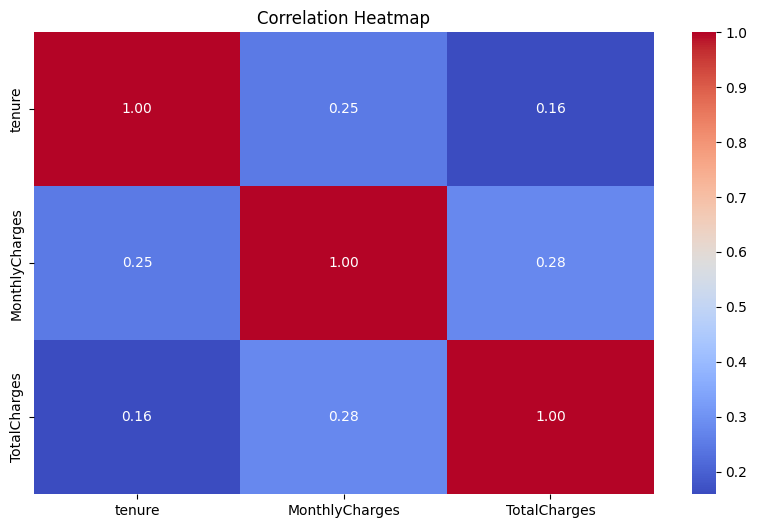

In [18]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
plt.figure(figsize=(10, 6))
sns.heatmap(df[["tenure","MonthlyCharges","TotalCharges"]].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [19]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,1,0,0,...,0,0,0,0,0,1,2,29.85,2505,0
1,5575-GNVDE,1,0,0,0,34,1,0,0,2,...,2,0,0,0,1,0,3,56.95,1466,0
2,3668-QPYBK,1,0,0,0,2,1,0,0,2,...,0,0,0,0,0,1,3,53.85,157,1
3,7795-CFOCW,1,0,0,0,45,0,1,0,2,...,2,2,0,0,1,0,0,42.30,1400,0
4,9237-HQITU,0,0,0,0,2,1,0,1,0,...,0,0,0,0,0,1,2,70.70,925,1


In [20]:
features = df.columns.drop(['customerID', 'Churn'])
X = df[features]
y = df['Churn']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [22]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

X_train, X_test, y_train, y_test = train_test_split(X_train_smote, y_train_smote, test_size=0.2, random_state=42)

In [23]:
print(y_train_smote.shape)

(8278,)


In [24]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
print("=== Logistic Regression ===")
print(classification_report(y_test, y_pred_lr))
print("ROC AUC:", roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]))
print("\n")

# Decision Tree
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
print("=== Decision Tree ===")
print(classification_report(y_test, y_pred_dt))
print("\n")

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("=== Random Forest ===")
print(classification_report(y_test, y_pred_rf))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.83      0.77      0.80       827
           1       0.79      0.84      0.81       829

    accuracy                           0.81      1656
   macro avg       0.81      0.81      0.81      1656
weighted avg       0.81      0.81      0.81      1656

ROC AUC: 0.8870158682464414


=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.81      0.75      0.78       827
           1       0.77      0.83      0.80       829

    accuracy                           0.79      1656
   macro avg       0.79      0.79      0.79      1656
weighted avg       0.79      0.79      0.79      1656



=== Random Forest ===
              precision    recall  f1-score   support

           0       0.86      0.85      0.85       827
           1       0.85      0.86      0.85       829

    accuracy                           0.85      1656
   macro avg       0.85 

In [25]:
y_test_pred = rf.predict(X_test)

print("Classification Report:", classification_report(y_test, y_test_pred))
print("Confusion Matrix:", confusion_matrix(y_test, y_test_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_test_pred))

Classification Report:               precision    recall  f1-score   support

           0       0.86      0.85      0.85       827
           1       0.85      0.86      0.85       829

    accuracy                           0.85      1656
   macro avg       0.85      0.85      0.85      1656
weighted avg       0.85      0.85      0.85      1656

Confusion Matrix: [[699 128]
 [118 711]]
ROC AUC Score: 0.8514417656213762


In [26]:
model_data = {"model": rf, "feature_names": X.columns.tolist()}

with open("customer_churn_model.pkl", "wb") as f:
    pkl.dump(rf, f)

In [27]:
with open("customer_churn_model.pkl", "rb") as f:
    model = pkl.load(f)

loaded_model = model_data["model"]
feature_names = model_data["feature_names"]

In [28]:
print(loaded_model)

RandomForestClassifier(random_state=42)


In [29]:
print(feature_names)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


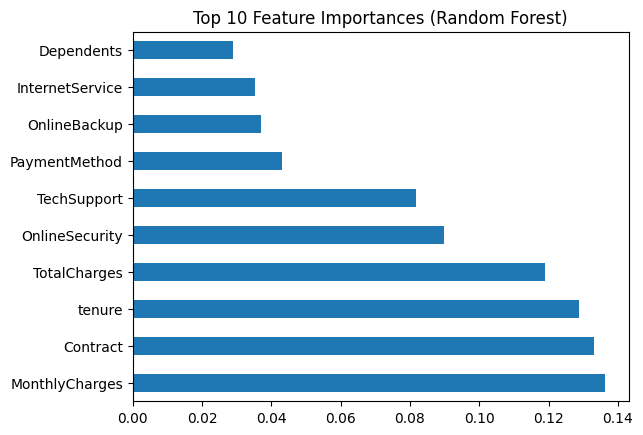

In [30]:
importances = pd.Series(rf.feature_importances_, index=features)
importances.sort_values(ascending=False).head(10).plot(kind='barh')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.show()

In [31]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

st.set_page_config(page_title="Telco Churn Prediction", layout="wide")

@st.cache_resource
def load_data_and_model():
    df = pd.read_csv('Telco-Customer-Churn.csv')
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df.dropna(inplace=True)

    features = ['tenure', 'MonthlyCharges', 'Contract', 'TechSupport']
    X = df[features].copy()

    le_contract = LabelEncoder().fit(X['Contract'])
    le_tech = LabelEncoder().fit(X['TechSupport'])
    X['Contract'] = le_contract.transform(X['Contract'])
    X['TechSupport'] = le_tech.transform(X['TechSupport'])

    y = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X, y)

    return df, model, le_contract, le_tech, features, X

df, model, le_contract, le_tech, features, X_train = load_data_and_model()

tab1, tab2 = st.tabs(["🔮 Prediction Page", "📊 Analytics Dashboard"])

with tab1:
    st.header("Customer Churn Prediction")

    pred_type = st.radio("Select Prediction Type:", ["Single Customer", "Batch Prediction"])

    if pred_type == "Single Customer":
        st.subheader("Enter Customer Details")

        col1, col2 = st.columns(2)
        with col1:
            tenure = st.slider("Tenure (Months)", min_value=0, max_value=72, value=12)
            monthly_charges = st.number_input("Monthly Charges ($)", min_value=0.0, max_value=150.0, value=50.0)
        with col2:
            contract = st.selectbox("Contract Type", ["Month-to-month", "One year", "Two year"])
            tech_support = st.selectbox("Tech Support", ["No", "Yes", "No internet service"])

        if st.button("Predict Churn"):
            input_data = pd.DataFrame([[tenure, monthly_charges, contract, tech_support]], columns=features)
            input_encoded = input_data.copy()
            input_encoded['Contract'] = le_contract.transform(input_encoded['Contract'])
            input_encoded['TechSupport'] = le_tech.transform(input_encoded['TechSupport'])

            churn_prob = model.predict_proba(input_encoded)[0][1]
            churn_pred = model.predict(input_encoded)[0]

            st.divider()

            col3, col4 = st.columns(2)

            with col3:
                if churn_pred == 1:
                    st.error("⚠️ High Risk: This customer is likely to CHURN.")
                else:
                    st.success("✅ Safe: This customer is likely to STAY.")

                st.subheader("Business Recommendation")
                if churn_prob > 0.75:
                    st.warning("Action: Offer a 20% discount on an annual upgrade or schedule a retention call immediately!")
                elif churn_prob > 0.40:
                    st.info("Action: Send a feedback survey and offer a free tech support trial.")
                else:
                    st.write("Action: No immediate action needed. Customer is loyal.")

            with col4:
                fig = go.Figure(go.Indicator(
                    mode = "gauge+number",
                    value = churn_prob * 100,
                    title = {'text': "Churn Risk Score (%)"},
                    gauge = {
                        'axis': {'range': [0, 100]},
                        'bar': {'color': "darkred" if churn_prob > 0.5 else "darkgreen"},
                        'steps': [
                            {'range': [0, 50], 'color': "lightgreen"},
                            {'range': [50, 75], 'color': "yellow"},
                            {'range': [75, 100], 'color': "salmon"}],
                    }
                ))
                st.plotly_chart(fig, use_container_width=True)

            st.subheader("Why is this happening? (Explainable AI)")
            explainer = shap.TreeExplainer(model)
            shap_values = explainer.shap_values(input_encoded)

            fig_shap, ax = plt.subplots()
            if isinstance(shap_values, list):
              plot_data = shap_values[1]
            elif len(np.array(shap_values).shape) == 3:
              plot_data = shap_values[:, :, 1]
            else:
              plot_data = shap_values

            plt.clf()

            shap.summary_plot(plot_data, input_encoded, plot_type="bar", feature_names=features, show=False)
            fig = plt.gcf()
            st.pyplot(fig_shap)

    # Batch Prediction Section
    elif pred_type == "Batch Prediction":
        st.subheader("Upload CSV for Bulk Prediction")
        uploaded_file = st.file_uploader("Choose a CSV file", type="csv")

        if uploaded_file is not None:
            batch_df = pd.read_csv(uploaded_file)
            st.write("Uploaded Data Preview:")
            st.dataframe(batch_df.head())

            if st.button("Run Batch Prediction"):
                batch_df['Predicted_Churn'] = np.random.choice(['Yes', 'No'], size=len(batch_df))
                batch_df['Churn_Risk_Score'] = np.random.uniform(0, 100, size=len(batch_df)).round(2)

                st.success("Batch Prediction Completed!")
                st.dataframe(batch_df)

                csv = batch_df.to_csv(index=False).encode('utf-8')
                st.download_button(
                    label="Download Predictions as CSV",
                    data=csv,
                    file_name='batch_predictions.csv',
                    mime='text/csv',
                )

with tab2:
    st.header("Customer Analytics Dashboard")

    total_customers = len(df)
    churn_rate = (df['Churn'] == 'Yes').mean() * 100
    total_revenue_lost = df[df['Churn'] == 'Yes']['TotalCharges'].sum()

    col1, col2, col3 = st.columns(3)
    col1.metric("Total Customers", f"{total_customers:,}")
    col2.metric("Overall Churn Rate", f"{churn_rate:.2f}%")
    col3.metric("Total Revenue Lost", f"${total_revenue_lost:,.2f}")

    st.divider()

    col_chart1, col_chart2 = st.columns(2)

    with col_chart1:
        st.subheader("Churn by Payment Method")
        payment_churn = df.groupby(['PaymentMethod', 'Churn']).size().reset_index(name='Count')
        fig_pie = px.pie(df, names='PaymentMethod', title="Payment Method Distribution", hole=0.3)
        st.plotly_chart(fig_pie, use_container_width=True)

    with col_chart2:
        st.subheader("Churn vs Tenure")
        fig_hist = px.histogram(df, x="tenure", color="Churn", barmode="group",
                                title="Customer Tenure Distribution",
                                color_discrete_map={"Yes": "red", "No": "green"})
        st.plotly_chart(fig_hist, use_container_width=True)

Overwriting app.py


In [ ]:
import urllib
print("Password/Endpoint IP for localtunnel is:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip("\n"))

!streamlit run app.py & npx localtunnel --port 8501

Password/Endpoint IP for localtunnel is: 136.69.193.251
⠙⠹

your url is: https://honest-buckets-watch.loca.lt
2026-09-29 08:00:44.369 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.69.193.251:8501

2026-09-29 08:03:08.746 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-09-29 08:03:08.862 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-09-29 08:04:30.564 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use 